# Home Credit Default Risk: Exploratory Data Analysis

Which applicant characteristics go with a higher chance of default, and what does that mean for the scoring model?

Every chart below shows the **default rate** (share of applicants with `TARGET = 1`) for a group of applicants. The dashed line is the overall rate.

**Data:** `application_train.csv` (307,511 applicants) joined with per-applicant aggregates from `bureau.csv`. Download both from Kaggle into `data/` (see the README).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.data_prep import load_bureau_aggregates

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})
ACCENT = "#2f6fdf"

DATA = Path.cwd().parent / "data"
df = pd.read_csv(DATA / "application_train.csv")
bureau_agg = load_bureau_aggregates(pd.read_csv(DATA / "bureau.csv"))
df = df.merge(bureau_agg, on="SK_ID_CURR", how="left")
df["has_bureau_record"] = df["bureau_count"].notna()
bureau_cols = [c for c in bureau_agg.columns if c != "SK_ID_CURR"]
df[bureau_cols] = df[bureau_cols].fillna(0)

OVERALL = df["TARGET"].mean()
print(f"{df.shape[0]:,} applicants, {df.shape[1]} columns")

307,511 applicants, 138 columns


## 1. Class balance

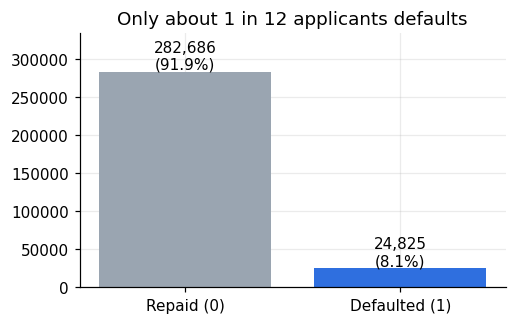

In [2]:
counts = df["TARGET"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["Repaid (0)", "Defaulted (1)"], counts.values, color=["#9aa5b1", ACCENT])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Only about 1 in 12 applicants defaults")
plt.show()

**Takeaway:** the default rate is **8.07%**. A model that predicts "repaid" for everyone would be about 92% accurate and useless, so accuracy is the wrong metric. This is why the project reports ROC-AUC, uses `scale_pos_weight`, and tunes the decision threshold for F1.

## 2. Data quality

In [3]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_EMPLOYED"]
missing = df[cols].isna().mean().sort_values(ascending=False)
print("Share of missing values in modelling columns:")
print((missing * 100).round(1).astype(str) + "%")

placeholder = df["DAYS_EMPLOYED"] == 365243
print(f"\nDAYS_EMPLOYED == 365243 (placeholder): {placeholder.mean():.1%} of rows")
print(df.groupby(placeholder)["TARGET"].mean().rename({False: "real value", True: "placeholder"}).map("{:.2%}".format))
print("\nIncome type of the placeholder rows:")
print(df.loc[placeholder, "NAME_INCOME_TYPE"].value_counts().head(3))

Share of missing values in modelling columns:
EXT_SOURCE_1       56.4%
EXT_SOURCE_3       19.8%
EXT_SOURCE_2        0.2%
AMT_GOODS_PRICE     0.1%
AMT_ANNUITY         0.0%
DAYS_EMPLOYED       0.0%
dtype: object

DAYS_EMPLOYED == 365243 (placeholder): 18.0% of rows
DAYS_EMPLOYED
real value     8.66%
placeholder    5.40%
Name: TARGET, dtype: object

Income type of the placeholder rows:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


**Takeaways**
- `EXT_SOURCE_1` is missing for **56.4%** of applicants, `EXT_SOURCE_3` for 19.8%. Missingness is common, so imputation choices matter.
- **18.0%** of rows carry the fake `DAYS_EMPLOYED = 365243` value (almost all pensioners). They default less often (**5.4%**) than rows with a real employment length (**8.7%**).
- The pipeline turns this placeholder into a missing value and fills it with the median, so that "this is a pensioner-style record" signal is lost. Adding an explicit `is_placeholder` flag is a cheap idea that has not been tested.

## 3. What separates defaulters from non-defaulters

In [4]:
def default_rate_chart(group, title, xlabel, rotate=0, min_n=0):
    stats = df.groupby(group, observed=True)["TARGET"].agg(rate="mean", n="size")
    stats = stats[stats["n"] >= min_n]
    labels = [str(i) for i in stats.index]
    fig, ax = plt.subplots(figsize=(max(5.5, 0.9 * len(stats) + 2), 3.4))
    ax.bar(labels, stats["rate"] * 100, color=ACCENT)
    ax.axhline(OVERALL * 100, color="#d9534f", ls="--", lw=1.2, label=f"overall {OVERALL:.1%}")
    for i, (rate, n) in enumerate(zip(stats["rate"], stats["n"])):
        ax.text(i, rate * 100, f"{rate:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, stats["rate"].max() * 100 * 1.25)
    ax.set_ylabel("Default rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right" if rotate else "center")
    plt.tight_layout()
    plt.show()
    return stats

### External credit scores

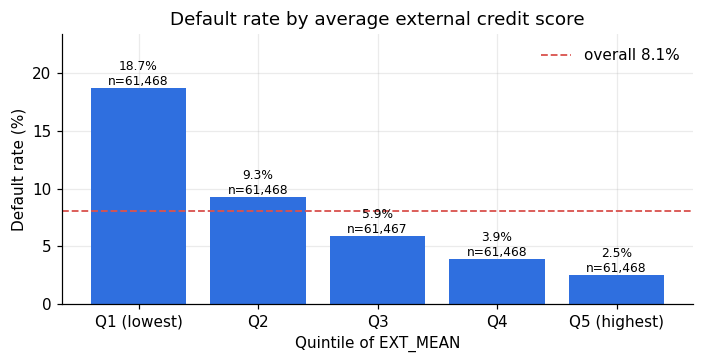

In [5]:
df["EXT_MEAN"] = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
df["ext_quintile"] = pd.qcut(df["EXT_MEAN"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
_ = default_rate_chart("ext_quintile", "Default rate by average external credit score", "Quintile of EXT_MEAN")

**Takeaway:** the strongest signal in the data. Default falls from **18.7%** in the lowest quintile to **2.5%** in the highest, about a 7.5× spread. `EXT_MEAN` also has the largest correlation with the target (-0.22, see section 5). This matches the SHAP result, where the external scores dominate.

### Age

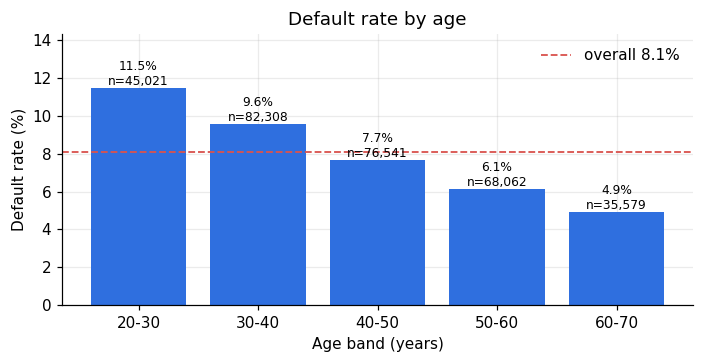

In [6]:
df["age_years"] = -df["DAYS_BIRTH"] / 365
df["age_band"] = pd.cut(df["age_years"], [20, 30, 40, 50, 60, 70], labels=["20-30", "30-40", "40-50", "50-60", "60-70"])
_ = default_rate_chart("age_band", "Default rate by age", "Age band (years)")

**Takeaway:** risk falls steadily with age, from **11.5%** for 20-30 year olds to **4.9%** for 60-70 year olds. Age is a legitimate underwriting factor in this dataset, but it is also a possible fairness concern (a protected attribute in many jurisdictions), which is noted in the README.

### Income

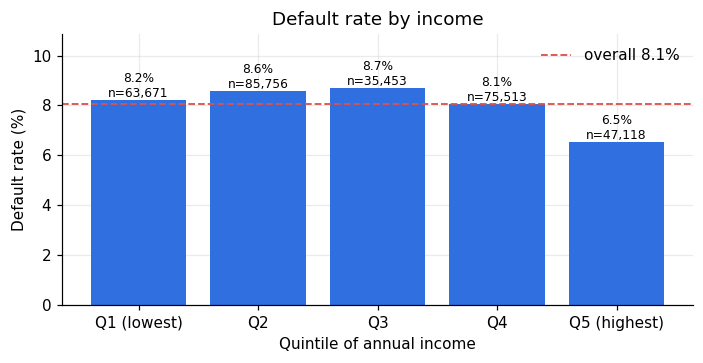

In [7]:
df["income_quintile"] = pd.qcut(df["AMT_INCOME_TOTAL"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
_ = default_rate_chart("income_quintile", "Default rate by income", "Quintile of annual income")

**Takeaway:** income alone is a weak signal. Quintiles 1 to 4 sit between **8.1% and 8.7%**, and only the top quintile is clearly lower (**6.5%**). Income matters more as a denominator in the ratios below than on its own.

### Loan size and repayment burden relative to income

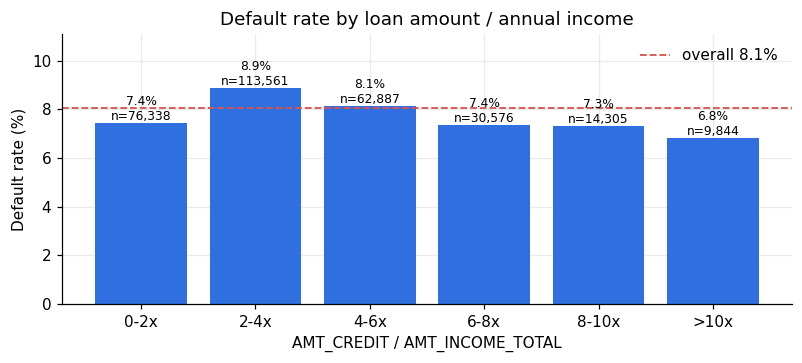

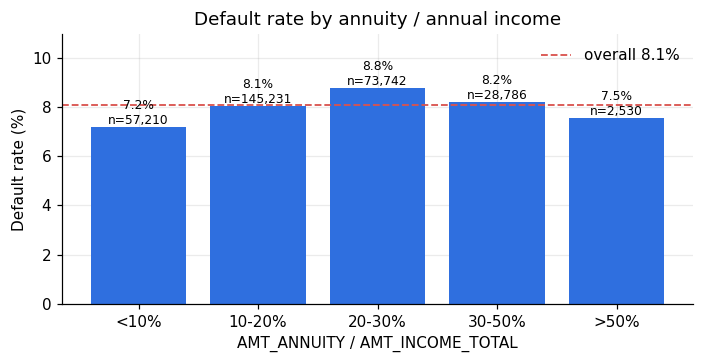

Median AMT_CREDIT / AMT_ANNUITY: 20.0


In [8]:
df["credit_to_income"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["annuity_to_income"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["cti_band"] = pd.cut(df["credit_to_income"], [0, 2, 4, 6, 8, 10, 100], labels=["0-2x", "2-4x", "4-6x", "6-8x", "8-10x", ">10x"])
df["ati_band"] = pd.cut(df["annuity_to_income"], [0, 0.1, 0.2, 0.3, 0.5, 100], labels=["<10%", "10-20%", "20-30%", "30-50%", ">50%"])
_ = default_rate_chart("cti_band", "Default rate by loan amount / annual income", "AMT_CREDIT / AMT_INCOME_TOTAL")
_ = default_rate_chart("ati_band", "Default rate by annuity / annual income", "AMT_ANNUITY / AMT_INCOME_TOTAL")
print("Median AMT_CREDIT / AMT_ANNUITY:", round((df["AMT_CREDIT"] / df["AMT_ANNUITY"]).median(), 1))

**Takeaway (this one is surprising):** the relationship is **not monotonic**. The riskiest loan-to-income band is 2-4x (**8.9%**), and applicants above 10x income default **less** often (**6.8%**, 9,844 applicants) than average. The same pattern holds for annuity-to-income: the >50% group is at **7.6%**, below the 20-30% group at **8.8%**.

What this means for the project:
- The README's policy caps (e.g. "annuity > 50% of income caps the score at 55") are **business rules, not something this data supports**. Applicants that extreme are rare (3.2% above 10x, 0.8% above 50%), and in this sample they are not worse payers. The guardrails are best described as lending-policy overrides.
- The tree model learns what it can from `CREDIT_INCOME_RATIO` and `ANNUITY_INCOME_RATIO`, but their raw relationship to default is weak.
- **Units:** the official column description says only "Loan annuity". It does not say whether the amount is per month or per year. The median `AMT_CREDIT / AMT_ANNUITY` is about 20, which fits either a roughly 20-payment loan or a roughly 20-year one. The dashboard's "yearly payment" label is therefore an assumption the data cannot confirm.

### Loan type, education and income source

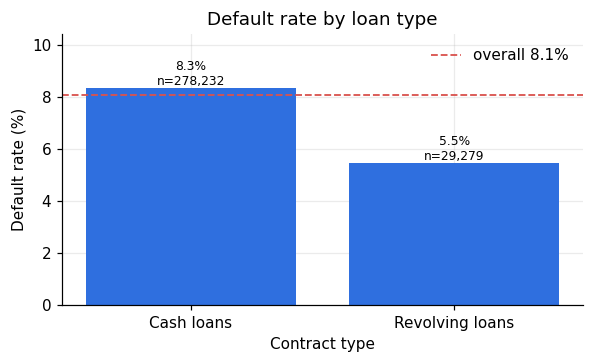

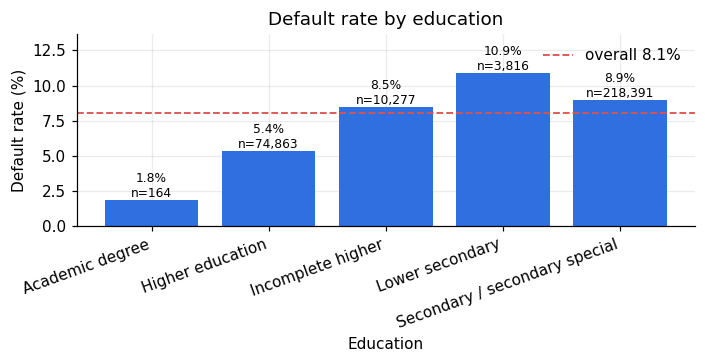

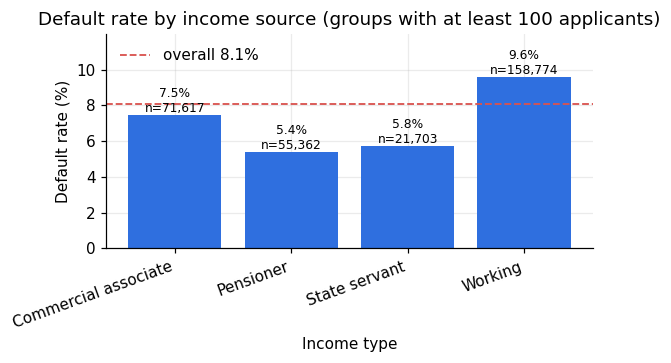

Groups hidden for having fewer than 100 applicants:
NAME_INCOME_TYPE
Unemployed         22
Student            18
Businessman        10
Maternity leave     5
Name: count, dtype: int64


In [9]:
_ = default_rate_chart("NAME_CONTRACT_TYPE", "Default rate by loan type", "Contract type")
_ = default_rate_chart("NAME_EDUCATION_TYPE", "Default rate by education", "Education", rotate=20)
_ = default_rate_chart("NAME_INCOME_TYPE", "Default rate by income source (groups with at least 100 applicants)", "Income type", rotate=20, min_n=100)
print("Groups hidden for having fewer than 100 applicants:")
small = df["NAME_INCOME_TYPE"].value_counts()
print(small[small < 100])

**Takeaways**
- **Revolving loans** default less (**5.5%**) than **cash loans** (**8.3%**).
- Education shows a clear gradient: **5.4%** for higher education vs **8.9%** for secondary and **10.9%** for lower secondary. (The academic-degree group is tiny, 164 applicants, so its 1.8% is not reliable.)
- **Working** applicants default more (**9.6%**) than **pensioners** (**5.4%**) or **state servants** (**5.8%**).
- The "Unemployed" group shows a 36% default rate, but it has only **22 applicants**, so it is hidden from the chart above. Do not read anything into it.

### Past credit (bureau)

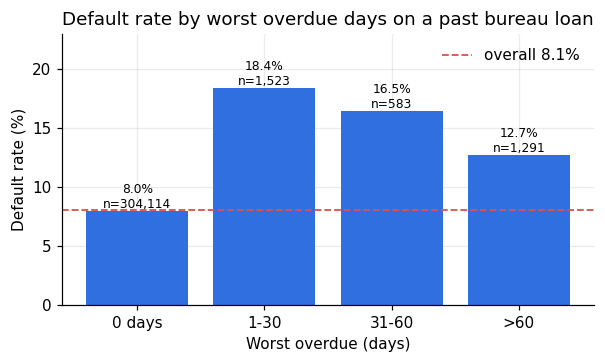

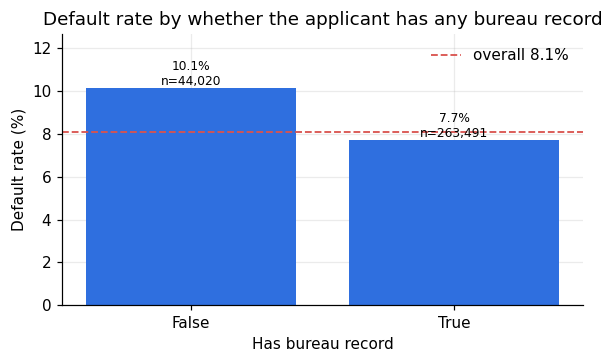

In [10]:
df["overdue_band"] = pd.cut(df["bureau_max_overdue"], [-1, 0, 30, 60, 1e9], labels=["0 days", "1-30", "31-60", ">60"])
_ = default_rate_chart("overdue_band", "Default rate by worst overdue days on a past bureau loan", "Worst overdue (days)")
_ = default_rate_chart("has_bureau_record", "Default rate by whether the applicant has any bureau record", "Has bureau record")

**Takeaways**
- Any past overdue is a strong warning sign: **12.7% to 18.4%** default vs **8.0%** for applicants with no overdue. However, only about **1.1%** of applicants (3,397) have one, so the signal is strong but narrow.
- Applicants with **no bureau record at all** default more often (**10.1%** vs **7.7%**). In `data_prep.py` they are filled with zeros, which makes "no history" look like a good-or-neutral record to the model. This works for trees because they can split on `bureau_count == 0`.
- Note that `bureau_max_overdue` is not monotonic either: the >60 day group (12.7%) is lower than the 1-30 day group (18.4%).

## 4. Correlation with default

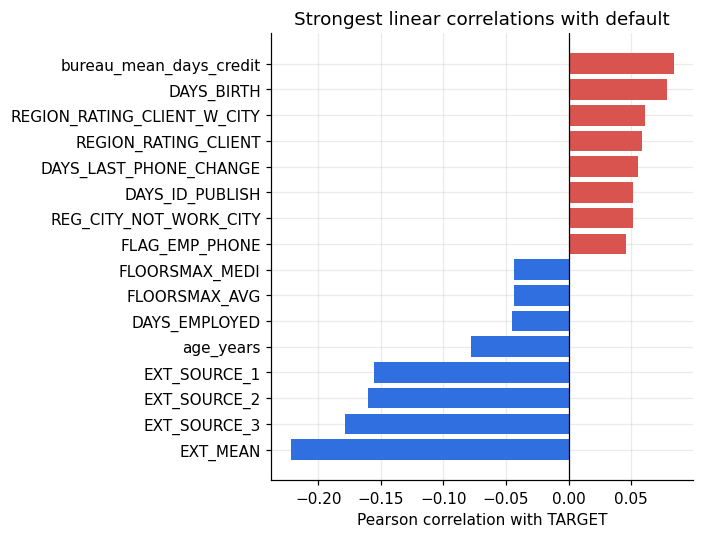

0.222 is the largest absolute correlation


In [11]:
corr = df.select_dtypes("number").drop(columns=["SK_ID_CURR"]).corrwith(df["TARGET"]).drop("TARGET").dropna()
top = pd.concat([corr.sort_values().head(8), corr.sort_values().tail(8)])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top.index, top.values, color=[ACCENT if v < 0 else "#d9534f" for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with TARGET")
ax.set_title("Strongest linear correlations with default")
plt.tight_layout()
plt.show()
print(corr.abs().max().round(3), "is the largest absolute correlation")

**Takeaway:** no single feature has a strong linear relationship with default. The largest is `EXT_MEAN` at **-0.22**, followed by the individual external scores and age. This explains the modest ROC-AUC (about 0.76) and why gradient-boosted trees, which capture non-linear interactions, were a good fit.

## 5. Summary

| Finding | Evidence | Implication |
|---|---|---|
| Heavy class imbalance | 8.07% default rate | Use ROC-AUC, class weighting, threshold tuning |
| External scores are the strongest signal | 18.7% vs 2.5% default across quintiles | Keep them and their interactions as core features |
| Age matters, income barely does | 11.5% to 4.9% across age bands, income flat for quintiles 1-4 | Age is a possible fairness concern, worth auditing |
| High loan-to-income is not riskier here | >10x income defaults at 6.8% | The policy caps are business rules, not data-driven |
| The `DAYS_EMPLOYED` placeholder carries signal | 18% of rows, 5.4% default vs 8.7% | Median imputation discards it, so a flag column is worth testing |
| Past overdue and missing bureau history both raise risk | up to 18.4% with overdue, 10.1% with no record | Already captured by `bureau_max_overdue` and `bureau_count` |
| No feature is strongly correlated with default | max |r| = 0.22 | Non-linear models fit, and a ceiling near ROC-AUC 0.76-0.80 is expected |

**Limits of this analysis:** these are descriptive, one-feature-at-a-time comparisons on the training file. They do not show causation, they ignore interactions between features, and small groups (such as the 22 unemployed applicants) are not reliable.